# Vectorless vs VectorDB RAG: head-to-head

> **Purpose of this notebook:** compare the three RAG systems fairly on the same 10 questions: which pages each one reads, how good the answers are (judged by Claude), and how fast and costly each is. It ends with charts and written findings. The script version is `evaluate.py`.

Same PDF, same 10 questions, same answering model (**Claude Sonnet**, on your Claude subscription). Only the **retrieval** changes.

| System | How it finds the text |
|---|---|
| **Vector RAG** | one similarity search in Chroma, top 5 chunks (`vectordb.ipynb`, plain graph) |
| **Agentic vector RAG** | similarity search, Claude grades the chunks, retries with a better query if needed (agentic graph) |
| **PageIndex (local)** | Claude reads the document tree and decides which pages to open (`pageindex.ipynb`, local tree) |

PageIndex **cloud** is left out: `PAGEINDEX_API_KEY` is commented out in `.env`.

### What we measure
| Metric | Meaning |
|---|---|
| **Hit** | did it read at least one correct page? |
| **Recall** | share of the correct pages it read |
| **Precision** | share of the pages it read that were correct (low = read a lot of noise) |
| **Pages read / chars read** | how much text the LLM had to read (cost driver) |
| **Latency** | seconds per question (each Claude call also has ~2 s of Claude Code start-up) |
| **LLM calls** | model calls per question |
| **Answer score** | 1-5, Claude judges each answer against the correct pages, answers shuffled and unlabeled |

Results are saved to `results/compare/runs.json`. Re-running skips finished runs, so it never repeats work.

## Setup

In [1]:
# Imports, paths and keys
import os, json, re, time, random, asyncio
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from typing import TypedDict, Literal

import numpy as np
from dotenv import load_dotenv

load_dotenv()
os.environ.pop("ANTHROPIC_API_KEY", None)   # make Claude Code use the subscription, not an API key

PROJECT_ROOT = Path.cwd().parents[2]        # notebook runs from src/.../compare
OUT_DIR = PROJECT_ROOT / "results" / "compare"
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_FILE = OUT_DIR / "runs.json"

print("OPENROUTER_API_KEY ->", "loaded" if os.getenv("OPENROUTER_API_KEY") else "MISSING")

OPENROUTER_API_KEY -> loaded


In [2]:
# Claude helper (same as vectordb.ipynb): text answer, or a dict when a JSON schema is given
from claude_agent_sdk import ClaudeAgentOptions, ResultMessage, query

CHAT_MODEL = "sonnet"

def ask_claude(prompt: str, system: str = "", schema: dict | None = None):
    options = ClaudeAgentOptions(
        model=CHAT_MODEL, system_prompt=system, tools=[], setting_sources=[], max_turns=1,
        output_format={"type": "json_schema", "schema": schema} if schema else None,
    )

    async def run():
        result = None
        async for message in query(prompt=prompt, options=options):
            if isinstance(message, ResultMessage):
                result = message
        if result is None or result.is_error:
            raise RuntimeError(f"Claude call failed: {getattr(result, 'result', None)}")
        return result.structured_output if schema else result.result

    with ThreadPoolExecutor(max_workers=1) as pool:   # works inside Jupyter's event loop
        return pool.submit(asyncio.run, run()).result()

## Vector RAG: open the existing Chroma DB
No re-embedding: the 71 chunks were stored by `vectordb.ipynb`. Only the questions need new vectors.

In [3]:
# Open the vector DB built in vectordb.ipynb
import chromadb
from openai import OpenAI
from chromadb.utils.embedding_functions import OpenAIEmbeddingFunction

EMBED_MODEL = "nvidia/nemotron-3.5-embed-1b:free"
openrouter = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.environ["OPENROUTER_API_KEY"])
embed_fn = OpenAIEmbeddingFunction(api_key_env_var="OPENROUTER_API_KEY", model_name=EMBED_MODEL,
                                   api_base="https://openrouter.ai/api/v1")

db = chromadb.PersistentClient(path=PROJECT_ROOT / "results" / "chroma_db")
collection = db.get_collection("attention_paper", embedding_function=embed_fn)
print("Chunks in DB:", collection.count())

Chunks in DB: 71


In [4]:
# retrieve + generate + both LangGraph graphs (same logic as vectordb.ipynb)
from langgraph.graph import StateGraph, START, END

TOP_K = 5
MAX_RETRIES = 2
_query_cache: dict[str, list[float]] = {}

def embed_many(texts: list[str]) -> None:
    """Embed several queries in ONE request and cache them."""
    todo = [t for t in texts if t not in _query_cache]
    if todo:
        resp = openrouter.embeddings.create(model=EMBED_MODEL, input=todo)
        for d in sorted(resp.data, key=lambda d: d.index):
            _query_cache[todo[d.index]] = d.embedding

def retrieve(text: str, k: int = TOP_K) -> list[dict]:
    embed_many([text])
    res = collection.query(query_embeddings=[_query_cache[text]], n_results=k)
    return [{"id": i, "page": m["page"], "text": d}
            for i, m, d in zip(res["ids"][0], res["metadatas"][0], res["documents"][0])]

ANSWER_SYSTEM = ("You answer questions about a research paper using ONLY the context given. "
                 "Cite pages like [p. 4]. If the context does not contain the answer, say so. Be concise.")

def format_context(chunks: list[dict]) -> str:
    return "\n\n".join(f"[p. {c['page']}] {c['text']}" for c in chunks)

def generate(question: str, chunks: list[dict]) -> str:
    return ask_claude(f"Context:\n{format_context(chunks)}\n\nQuestion: {question}", system=ANSWER_SYSTEM)

# Plain graph: START -> retrieve -> generate -> END
class RAGState(TypedDict, total=False):
    question: str
    chunks: list[dict]
    answer: str

g = StateGraph(RAGState)
g.add_node("retrieve", lambda s: {"chunks": retrieve(s["question"])})
g.add_node("generate", lambda s: {"answer": generate(s["question"], s["chunks"])})
g.add_edge(START, "retrieve"); g.add_edge("retrieve", "generate"); g.add_edge("generate", END)
rag_graph = g.compile()

# Agentic graph: retrieve -> grade -> (generate | retry -> retrieve)
GRADE_SCHEMA = {"type": "object",
                "properties": {"relevant": {"type": "boolean"}, "better_query": {"type": "string"}},
                "required": ["relevant", "better_query"]}

class AgentState(TypedDict, total=False):
    question: str
    search_query: str
    chunks: list[dict]
    relevant: bool
    retries: int
    grades: int
    chars_read: int
    queries_tried: list[str]
    answer: str

def a_retrieve(s):
    q = s.get("search_query") or s["question"]
    return {"chunks": retrieve(q), "queries_tried": s.get("queries_tried", []) + [q]}

def a_grade(s):
    ctx = format_context(s["chunks"])
    v = ask_claude(f"Question: {s['question']}\n\nContext:\n{ctx}\n\nDoes this context contain the answer? "
                   "If not, suggest a better search query using words likely to appear in the paper.",
                   schema=GRADE_SCHEMA)
    return {"relevant": v["relevant"], "search_query": v["better_query"],
            "grades": s.get("grades", 0) + 1, "chars_read": s.get("chars_read", 0) + len(ctx)}

def route(s) -> Literal["retry", "generate"]:
    return "generate" if s["relevant"] or s.get("retries", 0) >= MAX_RETRIES else "retry"

a = StateGraph(AgentState)
a.add_node("retrieve", a_retrieve)
a.add_node("grade", a_grade)
a.add_node("retry", lambda s: {"retries": s.get("retries", 0) + 1})
a.add_node("generate", lambda s: {"answer": generate(s["question"], s["chunks"])})
a.add_edge(START, "retrieve"); a.add_edge("retrieve", "grade")
a.add_conditional_edges("grade", route); a.add_edge("retry", "retrieve"); a.add_edge("generate", END)
agentic_graph = a.compile()
print("graphs ready")

graphs ready


## PageIndex (local): the vectorless side
Same local tree as `pageindex.ipynb`, but the chat model is now `claude-code/sonnet`, so both sides answer with the same model.
`.events` gives the run as typed events, so we can read exactly which pages Claude opened.

In [5]:
# PageIndex local client, answering with Claude through your subscription
from pageindex import PageIndexClient

pi_client = PageIndexClient(
    index={"model": "claude-code/sonnet", "storage_path": str(PROJECT_ROOT / "results" / "pageindex_local")},
    chat="claude-code/sonnet",
)
PI_DOC_ID = "pi-674f81e1daac4d75a9e3c7aed9d2949f"   # already indexed in pageindex.ipynb

def parse_pages(spec) -> set[int]:
    """'4-5' -> {4, 5};  '3,6' -> {3, 6}"""
    pages = set()
    for part in str(spec).split(","):
        part = part.strip()
        if "-" in part:
            lo, hi = part.split("-", 1)
            pages.update(range(int(lo), int(hi) + 1))
        elif part.isdigit():
            pages.add(int(part))
    return pages

def run_pageindex(question: str) -> dict:
    pages, chars, tool_calls, answer = set(), 0, 0, []
    for ev in pi_client.chat(question, doc_id=PI_DOC_ID, stream=True).events:
        if ev["type"] == "tool_call":
            tool_calls += 1
            if ev["name"] == "get_page_content":
                pages |= parse_pages(ev["arguments"].get("pages", ""))
        elif ev["type"] == "tool_result":
            chars += len(str(ev["output"]))          # everything the model had to read
        elif ev["type"] == "answer":
            answer.append(ev["delta"])
    return {"pages": sorted(pages), "chars_read": chars, "llm_calls": tool_calls + 1, "answer": "".join(answer)}

## The questions
Each question has **gold pages**: the pages of the PDF that actually contain the answer (checked by searching the page text).

In [6]:
# 10 questions with the pages that contain the answer
QUESTIONS = [
    {"id": "q1",  "question": "How does multi-head attention work?",                                                      "gold": [4, 5]},
    {"id": "q2",  "question": "What is the formula for scaled dot-product attention, and why are the dot products scaled?", "gold": [4]},
    {"id": "q3",  "question": "How are positional encodings computed?",                                                  "gold": [6]},
    {"id": "q4",  "question": "What optimizer and learning rate schedule were used for training?",                      "gold": [7]},
    {"id": "q5",  "question": "Which regularization techniques were used during training?",                             "gold": [7, 8]},
    {"id": "q6",  "question": "What hardware was used to train the models and how long did training take?",             "gold": [7]},
    {"id": "q7",  "question": "What BLEU scores did the big Transformer get on WMT 2014 English-German and English-French?", "gold": [1, 8]},
    {"id": "q8",  "question": "How well does the Transformer do on English constituency parsing?",                      "gold": [9, 10]},
    {"id": "q9",  "question": "How does changing the number of attention heads affect translation quality?",            "gold": [8, 9]},
    {"id": "q10", "question": "Why use self-attention instead of recurrent or convolutional layers?",                   "gold": [6, 7]},
]
SYSTEMS = ["Vector RAG", "Agentic vector RAG", "PageIndex (local)"]

embed_many([q["question"] for q in QUESTIONS])    # all 10 question vectors in a single request
print(len(QUESTIONS), "questions,", len(_query_cache), "query vectors cached")

10 questions, 10 query vectors cached


## Run every system on every question (cached, in parallel)

In [7]:
# One function per system, all returning the same fields
def run_system(system: str, question: str) -> dict:
    start = time.perf_counter()
    if system == "Vector RAG":
        out = rag_graph.invoke({"question": question})
        res = {"pages": sorted({c["page"] for c in out["chunks"]}), "llm_calls": 1,
               "chars_read": len(format_context(out["chunks"])), "answer": out["answer"]}
    elif system == "Agentic vector RAG":
        out = agentic_graph.invoke({"question": question})
        res = {"pages": sorted({c["page"] for c in out["chunks"]}), "llm_calls": out["grades"] + 1,
               "chars_read": out["chars_read"] + len(format_context(out["chunks"])), "answer": out["answer"],
               "queries_tried": out["queries_tried"]}
    else:
        res = run_pageindex(question)
    res["latency_s"] = round(time.perf_counter() - start, 1)
    return res

runs = json.loads(RUNS_FILE.read_text(encoding="utf-8")) if RUNS_FILE.exists() else {}
todo = [(s, q) for s in SYSTEMS for q in QUESTIONS if f"{s}|{q['id']}" not in runs]
print(f"{len(runs)} cached, {len(todo)} to run")

def job(item):
    s, q = item
    try:
        return f"{s}|{q['id']}", run_system(s, q["question"])
    except Exception as e:                     # one failure must not kill the whole batch
        return f"{s}|{q['id']}", {"error": f"{type(e).__name__}: {e}"}

with ThreadPoolExecutor(max_workers=4) as pool:   # 4 Claude runs at a time
    for key, res in pool.map(job, todo):
        if "error" in res:
            print("FAILED", key, res["error"][:200])
            continue
        runs[key] = res
        RUNS_FILE.write_text(json.dumps(runs, indent=2, ensure_ascii=False), encoding="utf-8")  # save as we go
        print(f"done {key:28s} pages={res['pages']}  {res['latency_s']}s")

30 cached, 0 to run


## Judge the answers
For each question, Claude sees the **gold pages' full text** and the three answers, **shuffled and unlabeled** (so it cannot favour a system by name), and scores each 1-5.

In [8]:
# LLM-as-judge, one call per question, cached in runs.json
from pypdf import PdfReader

with PdfReader(PROJECT_ROOT / "data" / "Attention.pdf") as reader:
    PAGE_TEXT = {i: p.extract_text() for i, p in enumerate(reader.pages, start=1)}

JUDGE_SCHEMA = {"type": "object", "properties": {"scores": {"type": "array", "items": {
    "type": "object",
    "properties": {"label": {"type": "string"}, "score": {"type": "integer", "minimum": 1, "maximum": 5},
                   "reason": {"type": "string"}},
    "required": ["label", "score", "reason"]}}}, "required": ["scores"]}

JUDGE_SYSTEM = ("You grade answers to a question about a research paper. Use the reference pages as ground truth. "
                "5 = fully correct and complete, 4 = correct with small gaps, 3 = partly correct, "
                "2 = mostly wrong or missing, 1 = wrong or no answer. Ignore style and length.")

def judge(q: dict) -> None:
    keys = [f"{s}|{q['id']}" for s in SYSTEMS]
    if all("score" in runs.get(k, {}) for k in keys) or not all(k in runs for k in keys):
        return                                              # already judged, or a run is missing
    order = keys[:]
    random.Random(q["id"]).shuffle(order)                   # same shuffle every time, different per question
    labels = {k: chr(65 + i) for i, k in enumerate(order)}  # A, B, C
    reference = "\n\n".join(f"[page {p}]\n{PAGE_TEXT[p]}" for p in q["gold"])
    answers = "\n\n".join(f"### Answer {labels[k]}\n{runs[k]['answer']}" for k in order)
    verdict = ask_claude(f"Reference pages:\n{reference}\n\nQuestion: {q['question']}\n\n{answers}",
                         system=JUDGE_SYSTEM, schema=JUDGE_SCHEMA)
    by_label = {s["label"].strip().upper()[-1]: s for s in verdict["scores"]}
    for k in keys:
        runs[k]["score"] = by_label[labels[k]]["score"]
        runs[k]["judge_reason"] = by_label[labels[k]]["reason"]

with ThreadPoolExecutor(max_workers=4) as pool:
    list(pool.map(judge, QUESTIONS))
RUNS_FILE.write_text(json.dumps(runs, indent=2, ensure_ascii=False), encoding="utf-8")
print("judged:", sum("score" in r for r in runs.values()), "/", len(runs))

judged: 30 / 30


## Results table

In [9]:
# One row per (system, question), then averages per system
import pandas as pd

rows = []
for q in QUESTIONS:
    gold = set(q["gold"])
    for s in SYSTEMS:
        r = runs.get(f"{s}|{q['id']}")
        if not r:
            continue
        got = set(r["pages"])
        rows.append({
            "system": s, "id": q["id"], "question": q["question"], "gold": sorted(gold), "pages": r["pages"],
            "hit": int(bool(got & gold)),
            "recall": len(got & gold) / len(gold),
            "precision": len(got & gold) / len(got) if got else 0.0,
            "pages_read": len(got), "chars_read": r["chars_read"], "latency_s": r["latency_s"],
            "llm_calls": r["llm_calls"], "score": r.get("score"),
        })
df = pd.DataFrame(rows)
df.to_csv(OUT_DIR / "per_question.csv", index=False)

summary = (df.groupby("system", sort=False)
             .agg(hit_rate=("hit", "mean"), recall=("recall", "mean"), precision=("precision", "mean"),
                  pages_read=("pages_read", "mean"), chars_read=("chars_read", "mean"),
                  latency_s=("latency_s", "mean"), llm_calls=("llm_calls", "mean"), score=("score", "mean"))
             .reindex(SYSTEMS).round(2))
summary.to_csv(OUT_DIR / "summary.csv")
summary

,hit_rate,recall,precision,pages_read,chars_read,latency_s,llm_calls,score
system,,,,,,,,
Vector RAG,1.0,1.00,0.62,2.7,3684.1,6.09,1.0,4.2
Agentic vector RAG,1.0,1.00,0.62,2.7,7368.2,11.74,2.0,4.1
PageIndex (local),1.0,0.95,0.72,2.1,8681.8,7.65,2.1,4.8


In [10]:
# Per-question view: which pages each system read (gold pages in the 'gold' column)
view = df.pivot(index="id", columns="system", values="pages").reindex([q["id"] for q in QUESTIONS])[SYSTEMS]
view.insert(0, "gold", [q["gold"] for q in QUESTIONS])   # the correct pages, for comparison
view

system,gold,Vector RAG,Agentic vector RAG,PageIndex (local)
id,,,,
q1,"[4, 5]","[4, 5]","[4, 5]","[3, 4, 5]"
q2,[4],"[4, 5]","[4, 5]","[3, 4]"
q3,[6],"[3, 5, 6]","[3, 5, 6]","[5, 6]"
q4,[7],"[7, 8]","[7, 8]","[7, 8]"
q5,"[7, 8]","[7, 8, 12]","[7, 8, 12]","[7, 8]"
q6,[7],"[2, 7, 8]","[2, 7, 8]","[7, 8]"
q7,"[1, 8]","[1, 8]","[1, 8]","[7, 8]"
q8,"[9, 10]","[1, 9, 10]","[1, 9, 10]","[9, 10]"
q9,"[8, 9]","[5, 8, 9, 10]","[5, 8, 9, 10]","[8, 9]"


## Charts
One measure per panel (never two scales on one axis). Colours follow the system, the same in every chart.

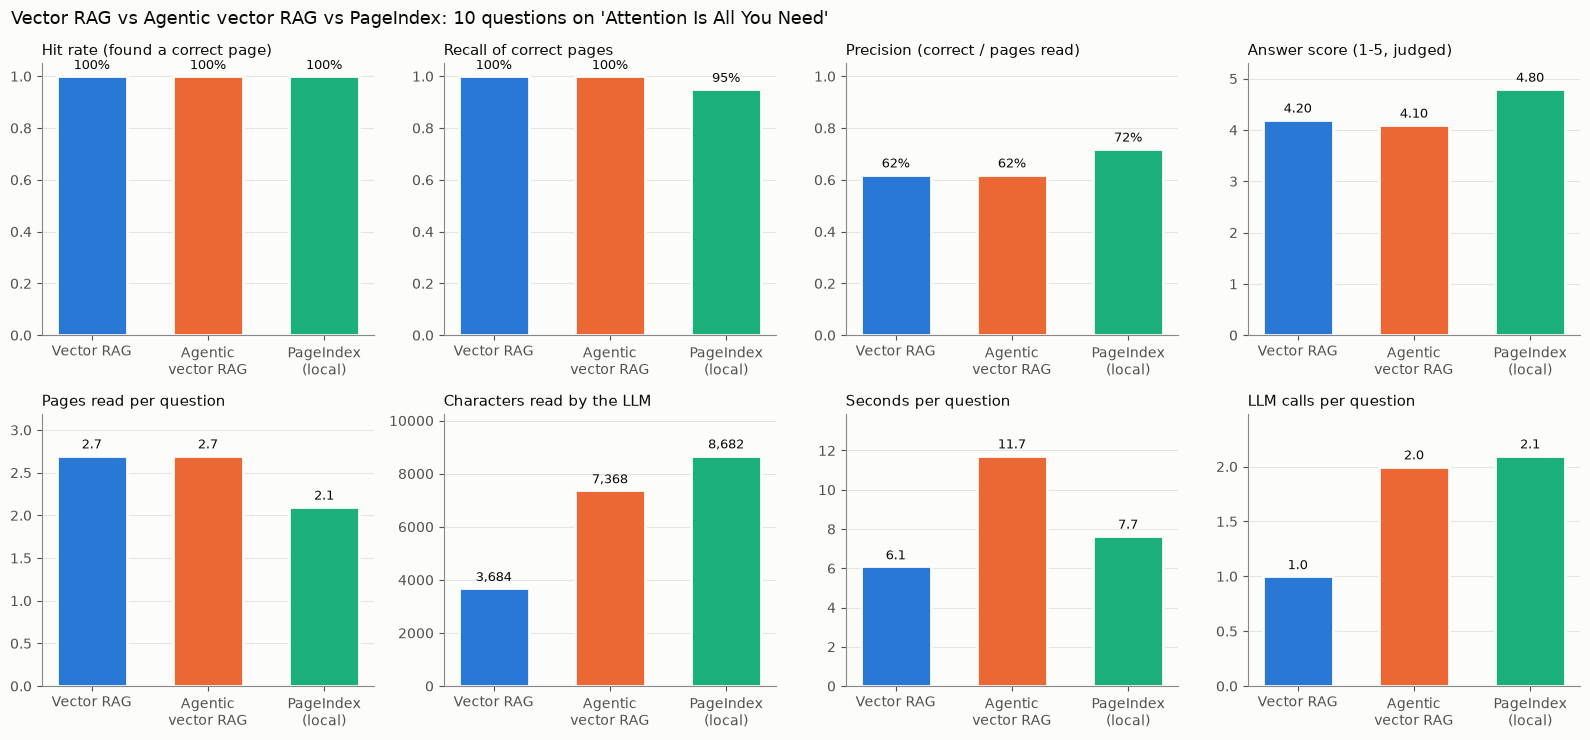

In [11]:
# Small multiples: one panel per metric, one bar per system
import matplotlib.pyplot as plt

COLORS = {"Vector RAG": "#2a78d6", "Agentic vector RAG": "#eb6834", "PageIndex (local)": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#888",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "font.size": 10, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})

PANELS = [("hit_rate", "Hit rate (found a correct page)", "{:.0%}", (0, 1.05)),
          ("recall", "Recall of correct pages", "{:.0%}", (0, 1.05)),
          ("precision", "Precision (correct / pages read)", "{:.0%}", (0, 1.05)),
          ("score", "Answer score (1-5, judged)", "{:.2f}", (0, 5.3)),
          ("pages_read", "Pages read per question", "{:.1f}", None),
          ("chars_read", "Characters read by the LLM", "{:,.0f}", None),
          ("latency_s", "Seconds per question", "{:.1f}", None),
          ("llm_calls", "LLM calls per question", "{:.1f}", None)]

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, (col, title, fmt, ylim) in zip(axes.flat, PANELS):
    vals = summary[col]
    bars = ax.bar(range(len(SYSTEMS)), vals, color=[COLORS[s] for s in SYSTEMS], width=0.6,
                  edgecolor="#fcfcfb", linewidth=2)
    for b, v in zip(bars, vals):                              # direct value labels, in text colour
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom",
                    xytext=(0, 3), textcoords="offset points", color="#0b0b0b", fontsize=9)
    ax.set_title(title, fontsize=11, color="#0b0b0b", loc="left")
    ax.set_xticks(range(len(SYSTEMS)), [s.replace(" (local)", "\n(local)").replace("Agentic ", "Agentic\n") for s in SYSTEMS])
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8); ax.set_axisbelow(True)
    if ylim: ax.set_ylim(*ylim)
    else: ax.set_ylim(0, vals.max() * 1.18)
fig.suptitle("Vector RAG vs Agentic vector RAG vs PageIndex: 10 questions on 'Attention Is All You Need'",
             fontsize=13, x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
fig.savefig(OUT_DIR / "summary.png", dpi=150)
plt.show()

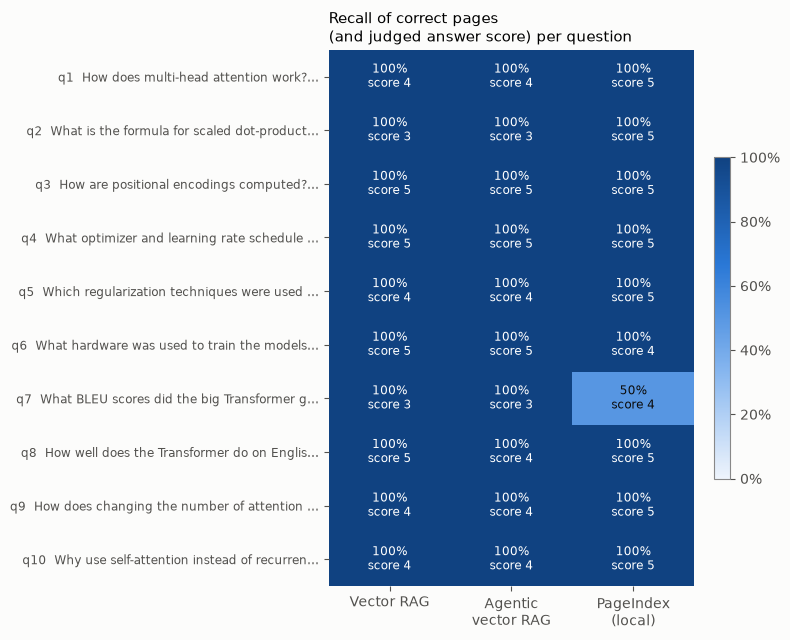

In [12]:
# Heatmap: recall per question and system (one hue, light = low, dark = high)
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#eef4fc", "#86b6ef", "#2a78d6", "#104281"])
grid = df.pivot(index="id", columns="system", values="recall").reindex([q["id"] for q in QUESTIONS])[SYSTEMS]
scores = df.pivot(index="id", columns="system", values="score").reindex(grid.index)[SYSTEMS]

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(grid.values, cmap=blues, vmin=0, vmax=1, aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.0%}\nscore {scores.values[i, j]:.0f}", ha="center", va="center", fontsize=8.5,
                color="#ffffff" if v > 0.6 else "#0b0b0b")
labels = {q["id"]: f"{q['id']}  {q['question'][:42]}…" for q in QUESTIONS}
ax.set_yticks(range(len(grid)), [labels[i] for i in grid.index], fontsize=8.5)
ax.set_xticks(range(len(SYSTEMS)), [s.replace(" (local)", "\n(local)").replace("Agentic ", "Agentic\n") for s in SYSTEMS])
ax.set_title("Recall of correct pages\n(and judged answer score) per question", loc="left", fontsize=11)
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, format=lambda x, _: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUT_DIR / "recall_heatmap.png", dpi=150)
plt.show()

## Findings

| | Vector RAG | Agentic vector RAG | PageIndex (local) |
|---|---|---|---|
| Hit rate | 100% | 100% | 100% |
| Recall of correct pages | **100%** | **100%** | 95% |
| Precision | 62% | 62% | **72%** |
| Answer score (1-5) | 4.2 | 4.1 | **4.8** |
| Seconds / question | **6.1** | 11.7 | 7.7 |
| Characters read | **3.7k** | 7.4k | 8.7k |
| LLM calls | **1** | 2 | 2.1 |

### 1. Finding the right page was easy for everyone
On a short, well-structured 15-page paper, every system reached a correct page for every question.
Vector search even had perfect recall: 5 chunks usually span ~3 pages, so they cover the gold pages, but with more noise (62% precision).

### 2. The answers differ because of *what* the LLM reads, not *where* it looks
Vector RAG gives Claude five 120-word **fragments**. The judge's most common complaint about vector answers was
*"it says the table / footnote is cut off, but the reference page contains it"* (q2, q7, q9, q10).
PageIndex opens **whole pages**, so tables (Table 2 BLEU, Table 3 head counts) and footnotes arrive intact.
Example q9 (attention heads): vector answers had no numbers; PageIndex quoted Table 3 row by row (h=1: 24.9 BLEU … h=16: 25.8).

### 3. Agentic RAG paid double and gained nothing here
The grader called the first search "relevant" for all 10 questions, so it never retried: 2x the calls and time for the same chunks.
It asks *"does the context contain the answer?"*, and partial context passes. A stricter check (*"is it complete?"*) or a bigger `TOP_K` on retry would make the loop useful.

### 4. Speed and cost
Vector RAG is the cheapest: 1 LLM call, the least text. PageIndex reads ~2.4x more characters (tree + full pages) but is only ~1.5 s slower,
because its model turns run inside one Claude Code process (one start-up), while agentic RAG starts Claude twice.

### Caveats
- 10 questions on one short paper: a small sample, and an easy document for vector search.
- The judge is Claude, the same family as the answering model; answers were shuffled and unlabeled to limit bias.
- PageIndex sometimes added correct facts from the model's own memory (FLOPs in q6); the judge flagged them as "not on the shown page".
- Latency includes ~2 s of Claude Code start-up per call.

### What would help vector RAG catch up
Bigger chunks, or **parent-page retrieval** (search small chunks, then send the whole page they came from), would fix the cut-off tables while keeping cheap similarity search.

Full write-up: [notes/vectordb_vs_vectorless.md](../../../notes/vectordb_vs_vectorless.md)